# UFC Fight Predictor

**Project Question: Can public fight statistics predict UFC fights better than the betting market?**

In short: not on their own. On a testing dataset of 958 fights, a model only using statistics achieves 61.4% accuracy. This is better than always picking the red corner (55.3% accuracy), but below the betting market (69.8% accuracy). Adding the statistics to the market's odds gives 70.4%, but the difference from the market alone is not statistically significant, as closing odds already price in what public statistics know.

MMA is an incredibly unpredictable sport, with only a fraction of the data compared to the majority of popular sports, due to its recent invention (only becoming legitimized within the last 30 years). The goal of this project is to beat the closing odds posted of a fight. These odds typically have public statistics, injury news, and camp information embedded into them.

In [2]:
import pandas as pd
import sqlite3
import datetime
from tqdm.auto import tqdm
import numpy as np
import matplotlib.pyplot as plt

### Update ELO

[For more info about ELO click here.](https://www.geeksforgeeks.org/dsa/elo-rating-algorithm/)

In [3]:
def update_elo(rating_a:int, rating_b:int, a_won:int, k=32):
    '''
    Update the ELO of 2 fighters
    
    Parameters: 
    rating_a (int): fighter_a's ELO
    rating_b (int): fighter_b's ELO
    a_won (bool): if fighter_a won
    k (int): constant factor (max number of points lost or gained)
    
    Returns:
    Updated ELO scores.
    '''
    expected_a = 1 / (1 + 10 ** ((rating_b - rating_a) / 400))
    expected_b = 1 - expected_a

    score_a = 1 if a_won else 0
    score_b = 1 - score_a

    new_a = rating_a + k * (score_a - expected_a)
    new_b = rating_b + k * (score_b - expected_b)

    return round(new_a), round(new_b)

# Data

There a 2 sources of data used to make MMA fight predictions in this project. First is every event, fight, and fighter statistic from [ufcstats.com](http://ufcstats.com/statistics/events/completed). Pages were parsed by simulating the browser with Playwright and downloading them locally, and then scraping information using BeautifulSoup. In total, data encompassing 790 events, consisting of 8909 fights, and 2762 fights was collected.

The second is a public database of closing fight odds for roughly 3/4 of all fights in the UFC starting since 2010. The data can be viewed publicly [here](https://www.kaggle.com/datasets/jerzyszocik/ufc-betting-odds-daily-dataset). Each fight's odds were turned into probabilities, with the bookmaker's margin removed. If several books provide odds for a fight, the median valuewas taken as the market consensus for each fight.


### Load the Scraped data

Load the data for each event, fight, and fighters.

In [4]:
conn = sqlite3.connect("ufc.db")
# get all the events
events = pd.read_sql("SELECT * FROM events", conn)
# convert dates into date format
events['date'] = events['date'].apply(lambda d: datetime.datetime.strptime(d, '%Y-%m-%d'))
# convert fight ids from a list to a string
events['fight_ids'] = events["fight_ids"].apply(lambda x: x.split(','))
# sort events by date
events = events.sort_values('date')

# get all of the fights (use combined data)
fights = pd.read_sql("SELECT * FROM combined_fight_info", conn)
# need to add the date for every single fight
fights["date"] = fights["event_id"].map(events.set_index("event_id")["date"])
fights['date'] = pd.to_datetime(fights['date'])
# map fight formats to length
fights['max_fight_time_seconds'] = fights['time_format'].map({"3 Rnd (5-5-5)":900, "5 Rnd (5-5-5-5-5)":1500})
# sort by date
fights = fights.sort_values('date')

# grab all of the fighters
fighters = pd.read_sql("SELECT * FROM fighters", conn)
# convert date, add ELO
fighters['fighter_DOB'] = pd.to_datetime(fighters['fighter_DOB'])

conn.close()

### Load the Betting odds
Load the betting odds into a DataFrame.

In [5]:
# get bettings odds
betting_odds = pd.read_csv('bettingodds.csv')
# remove url prefix from betting odds
betting_odds['fight_url'] = betting_odds['fight_url'].str.removeprefix('http://ufcstats.com/fight-details/')
betting_odds['fighter_1_url'] = betting_odds['fighter_1_url'].str.removeprefix('http://ufcstats.com/fighter-details/')
betting_odds['fighter_2_url'] = betting_odds['fighter_2_url'].str.removeprefix('http://ufcstats.com/fighter-details/')
# convert date from string to date format
betting_odds['event_date'] = pd.to_datetime(betting_odds['event_date'])
# only want odds before and including UFC 331
betting_odds = betting_odds[betting_odds['event_date'] <= datetime.datetime.strptime('2026-09-19', '%Y-%m-%d')]

/var/folders/_0/4rm3hzyn16q6rgdj_2b2nxzc0000gn/T/ipykernel_2035/1078084878.py:2: DtypeWarning: Columns (0: fight_url, 1: fighter_1_url, 2: fighter_2_url) have mixed types. Specify dtype option on import or set low_memory=False.
  betting_odds = pd.read_csv('bettingodds.csv')


# Features

Every feature is calculated at a given point-in-time. It uses data before the fight being predicted in order to determine accurate information for a moment in time. Features include: wins, losses, KO/TKO wins/losses, decision wins/losses, win rates, loss rates, win streaks, closing betting odds, and ELO. Each fight is one row. 

The features are the difference between fighter 1 and fighter 2. For instance: age_diff. The label (and what the model is trying to predict) is whether fighter 1 won.

### General Features
Non-numeric features.

In [6]:
# columns to keep for each fight that are do not need differences calculated for them
general_cols = ['fight_id', 'event_id', 'event_name', 'winner_id', 'weight_class', 'is_title_fight', 'method', 'method_details', 'end_round', 'end_time_seconds', 'time_format', 'fight_duration_seconds', 'referee', 'date', 'max_fight_time_seconds']

### Fighter History

Get the fighting history for a given fighter.

In [7]:
def fighter_history(fighter_id:str, before_date:datetime.datetime.date):
    '''
    Collect the fighter history of a given fighter before a given date as a DataFrame
    
    Parameters:
    fighter_id (str): a unique fighter identifier
    before_data (date): a cutoff date before which to get information
    
    Returns:
    A DataFrame containing all of fight data of a given fighter
    '''
    # only serch through fights before current date
    past = fights[fights["date"] < before_date]

    parts = []
    # check if current fighter is fighter_1 or fighter_2
    for side in ("fighter_1_", "fighter_2_"):
        # get either the fighter_1 or fighter_2 columns
        own_cols = [c for c in fights.columns if c.startswith(side)]
        # collect all data for a given fighter for a given side if it exists
        rows = past.loc[past[f"{side}id"] == fighter_id, general_cols + own_cols]
        # remove the side prefix
        parts.append(rows.rename(columns=lambda x: x.removeprefix(side)))
    
    # return the fight data sorted by date
    return pd.concat(parts).sort_values("date").reset_index(drop=True)

### Fighter History with Extra Features

Load the fighter's history with extra features (statistics calculation).

In [8]:
def fighter_history_with_extra_features(fighter_id, before_date):
    '''
    Calculate extra features for each fighter
    
    Parameters:
    fighter_id (str): a unique fighter identifier
    before_data (date): a cutoff date before which to get information
    
    Returns:
    A DataFrame (1, N) containing all of the features for a given fighter
    '''
    # get all of a fighters old fights
    prev_fights = fighter_history(fighter_id, before_date)
    
    # calculate a fighter's win streak
    reset = (prev_fights["winner_id"] != fighter_id).cumsum()
    prev_fights["win_streak"] = (prev_fights["winner_id"] == fighter_id).groupby(reset).cumsum()
    
    # calculate current win streak and longest win streak
    if prev_fights.empty:
        longest_win_streak = 0
        current_win_streak = 0
        
    else:
        longest_win_streak = max(prev_fights['win_streak'])
        current_win_streak = prev_fights['win_streak'].iloc[-1]
    
    # calculate a fighter's age (divide by 365.25 for more accuracy)
    fighter_age = (before_date - fighters[fighters['fighter_id'] == fighter_id]['fighter_DOB']).item().days / 365.25
    
    # calculate days since debut and last fight
    if not prev_fights.empty:
        days_since_debut = (before_date - prev_fights.iloc[0]['date']).days
        days_since_last_fight = (before_date - prev_fights.iloc[-1]['date']).days
    else:
        days_since_debut = 0
        days_since_last_fight = 0
    
    # drop (most of) the non-numeric columns in order to calculate differences
    prev_fights = prev_fights.drop(columns=[
        'fight_id', 'event_id', 'event_name', 'weight_class', 'method_details', 'time_format', 'id', 'name', 'winner_id', 'date',
        'referee'
    ])
    
    # calculate fighter record
    prev_fights['wins'] = (prev_fights['result'] == 'W').astype(int)
    prev_fights['losses'] = (prev_fights['result'] == 'L').astype(int)
    prev_fights['draws'] = (prev_fights['result'] == 'D').astype(int)

    # method of fighter win
    prev_fights['KO/TKO_finish_wins'] = ((prev_fights['method'] == 'KO/TKO') & (prev_fights['wins'] == 1)).astype(int)
    prev_fights['Decision_finish_wins'] = ((prev_fights['method'].str.contains('Decision', na=False)) & (prev_fights['wins'] == 1)).astype(int)
    
    # method of fighter loss
    prev_fights['KO/TKO_finish_losses'] = ((prev_fights['method'] == 'KO/TKO') & (prev_fights['wins'] == 0)).astype(int)
    prev_fights['Decision_finish_losses'] = ((prev_fights['method'].str.contains('Decision', na=False)) & (prev_fights['wins'] == 0)).astype(int)

    # this will be summed together at a later step to give the total number of fights
    prev_fights['total_fights'] = 1
    
    # drop remaining non numeric columns now that they have been converted to numeric ones
    prev_fights = prev_fights.drop(columns=['method', 'result'])
    
    # calculate totals for a fight
    totals = prev_fights.sum(numeric_only=True)
    
    # perform division if possible
    def safe_div(numerator, denominator):
        return numerator / denominator if denominator else float("nan")
    
    # calculate total fights won
    totals['win_rate'] = safe_div(totals['wins'], totals['total_fights'])
    # total strikes landed
    landed = [x for x in totals.index.tolist() if 'landed' in x.lower()]
    # total strikes attempted
    attempted = [x for x in totals.index.tolist() if 'attempted' in x.lower()]
    
    # calculate a success rate (%) for all attack methods (ex. strikes, takedowns, etc.)
    for i, l in enumerate(landed):
        totals[f'{l.removesuffix('landed')}success_rate'] = safe_div(totals[l], totals[attempted[i]])
    
    # set previously calculated values into totals
    totals['days_since_last_fight'] = days_since_last_fight
    totals['days_since_debut'] = days_since_debut
    
    totals['finish_win_rate'] = safe_div(totals['KO/TKO_finish_wins'], totals['wins'])
    totals['decision_win_rate'] = safe_div(totals['Decision_finish_wins'], totals['wins'])
    totals['finish_loss_rate'] = safe_div(totals['KO/TKO_finish_losses'], totals['losses'])
    totals['decision_loss_rate'] = safe_div(totals['Decision_finish_losses'], totals['losses'])
    
    totals['fighter_age'] = fighter_age
    totals['current_win_streak'] = current_win_streak
    totals['current_win_streak_percent_of_career'] = safe_div(current_win_streak, prev_fights.shape[0])
    totals['longest_win_streak'] = longest_win_streak
    totals['longest_win_streak_percent_of_career'] = safe_div(longest_win_streak, prev_fights.shape[0])
    
    return totals

### Get Fight Statistics for a Given Fight

Get the statistics for a given fight, for both fighters, for all fights

In [9]:
# reset fighter ELO to avoid memory leaks
fighters['ELO'] = 1500
# database rows
rows = []

# iterate through previous events to calculate each fighter's history + visualize with progress bar
for e in tqdm(events.itertuples(), total=len(events)):
    # go through every fight in a card and calculate rows to add to training/fine tuning/testing data
    for f in e.fight_ids:
        # get the current fight and
        current_fight = fights[fights['fight_id'] == f]
        
        # get each fighter's ID
        f1_id = current_fight["fighter_1_id"].item()
        f2_id = current_fight["fighter_2_id"].item()
        # get fight date
        fight_date = current_fight["date"].item()

        # get fighter features
        history_fighter_1 = fighter_history_with_extra_features(f1_id, fight_date)
        history_fighter_2 = fighter_history_with_extra_features(f2_id, fight_date)

        # add prefix to each fighter correctly
        history_fighter_1_named = history_fighter_1.add_prefix("fighter_1_")
        history_fighter_2_named = history_fighter_2.add_prefix("fighter_2_")

        # get all other column headers that are not numbers 
        context = current_fight[general_cols + ["fighter_1_id", "fighter_2_id"]].iloc[0]
        # label each item as a winner or loser
        label = pd.Series({"label": int(current_fight["winner_id"].item() == f1_id)})

        # combine together: context, difference, label
        combined_row = pd.concat([
            context,
            (history_fighter_1 - history_fighter_2).add_suffix("_diff"),
            label,
        ])
        
        # grab old fighter ELO
        old_fighter_1_elo = fighters[fighters['fighter_id'] == f1_id]['ELO'].item()
        old_fighter_2_elo = fighters[fighters['fighter_id'] == f2_id]['ELO'].item()
        
        # add old fighter ELOs + calculate difference
        combined_row['fighter_1_elo'] = old_fighter_1_elo
        combined_row['fighter_2_elo'] = old_fighter_2_elo
        combined_row['ELO_diff'] = old_fighter_1_elo - old_fighter_2_elo
        
        # calculate new fighter ELOs
        new_fighter_1_elo, new_fighter_2_elo = update_elo(old_fighter_1_elo, old_fighter_2_elo, label.item())
        
        # update fighter ELOs
        fighters.loc[fighters.index[fighters['fighter_id'] == f1_id].item(), 'ELO'] = new_fighter_1_elo
        fighters.loc[fighters.index[fighters['fighter_id'] == f2_id].item(), 'ELO'] = new_fighter_2_elo
        
        # get the fighting odds for each fighter (check for both fighters)
        f1f1_match = (betting_odds['fighter_1'] == current_fight['fighter_1_name'].item())
        f2f1_match = (betting_odds['fighter_2'] == current_fight['fighter_1_name'].item())
        # check for the betting odds for the current date
        odds_exist = (f1f1_match | f2f1_match) & (betting_odds['event_date'] == current_fight['date'].item())
        
        if odds_exist.any():
            # get the odds for a specific fight
            odds_row = betting_odds[odds_exist]
            s = f1f1_match.loc[odds_row.index]
            f1_odds = odds_row['odds_1'].where(s, odds_row['odds_2'])
            f2_odds = odds_row['odds_2'].where(s, odds_row['odds_1'])
            # convert odds to a percentage
            imp1, imp2 = 1 / f1_odds, 1 / f2_odds
            # calculate logit
            f1_prob = np.clip((imp1 / (imp1 + imp2)).median(), 0.01, 0.99)
            combined_row['odds_logit'] = np.log(f1_prob / (1 - f1_prob))
        else:
            # if no odds found, then set to 0
            f1_prob = np.nan
            f2_prob = np.nan
            combined_row['odds_logit'] = np.nan
        
        # remove the current fight's outcome (no data leakage)
        combined_row = combined_row.drop(
            ["winner_id", "method", "method_details", "end_round", "end_time_seconds", "fight_duration_seconds"],
            errors="ignore",
        )
        
        # add fight row
        rows.append(combined_row)

# convert all rows into pandas df + save
df = pd.DataFrame(rows)
df.to_csv('all_train_test.csv', index=False)

  0%|          | 0/790 [00:00<?, ?it/s]

# Modelling

Training is split in time order. It is trained using fights from June 2015 onwards (around the start of USADA anti-doping testing), but fighter history from earlier is still fed into the model. Only fights with available odds are used. The first 80% is used to train the model with the remaining 20% held out for testing.

In order to prevent a fighter bias (fighter 1 or 2) from appearing, corner-blind training is used (every fight appears twice, once with the red and blue corners swapped), so the model can't learn a preference for the red or blue corner.

A model is selected using a grid search over regularized logistic regression (L1, L2 and elastic net; standard and quantile scaling; spline features), with time-ordered 5-fold cross-validation, scored by log loss.

Other models including XGBoost, LightGBM, random forest, extra trees, SVM, and LDA were tested, but none meaningfully beat Logistic Regression. The data was likely simple enough that logistic regression could effectively capture it, but there was not enough meaningful training data that could be used to meaningfully develop relationships for tree models.

In [10]:
def flip_fighters(X, y):
    """
    Return a copy with fighter 1 and fighter 2 swapped in every row and the differences signs swapped.
    
    Parameters:
    X: features
    y: labels
    
    Returns:
    X and y flipped
    """
    # copy of X and y
    X, y = X.copy(), y.copy()
    # get columns that need to have their signs flipped
    signed = [c for c in X.columns if '_diff' in c or c in ('odds_logit',)]
    # flip the signs
    X[signed] = -X[signed]
    # flip fighter_1 and fighter_2 values
    for c1 in [c for c in X.columns if c.startswith('fighter_1_')]:
        c2 = 'fighter_2_' + c1[len('fighter_1_'):]
        if c2 in X.columns:
            X[[c1, c2]] = X[[c2, c1]].values
    
    # subtract 1 from y (1 -> 0, 0 -> 1)
    return X, 1 - y


def mirror(X, y):
    """
    Returns a df with fighters in both order (model doesn't prefer one fighter over another)
    
    Parameters:
    X: features
    y: labels
    
    Returns:
    X and y flipped and placed together into one df
    """
    # get the flipped fighter data
    X_flip, y_flip = flip_fighters(X, y)
    # add both the flipped and unflipped data to train off
    X_both = pd.concat([X, X_flip]).sort_index(kind='stable')
    y_both = pd.concat([y, y_flip]).sort_index(kind='stable')
    return X_both, y_both

### Train the Model

Train the machine learning model to predict.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import QuantileTransformer, SplineTransformer, StandardScaler

import warnings

warnings.filterwarnings("ignore")

# get training data
df = pd.read_csv('all_train_test.csv')
df = df.sort_values('date').reset_index(drop=True)
# select fights after 2015
df = df[df['date'] >= '2015-06-01']

# drop non-numeric columns
df = df.drop(columns=['fight_id', 'event_id', 'event_name', 'weight_class', 'referee', 'date', 'fighter_1_id', 'fighter_2_id', 'time_format', 'is_title_fight_diff'])

# how much of the model to use to train (1-train_amount is what is left to test)
train_amount = 0.8

df = df.copy()
# only use columns that have odds
df['has_odds'] = df['odds_logit'].notna().astype(int)
df['odds_logit'] = df['odds_logit'].fillna(0)
df = df.fillna(0)
df = df.loc[(df['has_odds'] == 1).values]

# cutoff for training
train_index = int(len(df) * train_amount)

# market odds - compare to model (pick favourite)
gambler_logit = (df['odds_logit'] > 0).astype(int)[train_index:].values

# train and test df
train_df = df.iloc[:train_index]
test_df = df.iloc[train_index:]

# mirror the training data (don't pick one corner over the other)
X_train = train_df.drop(columns=['label'])
y_train = train_df['label']
X_train, y_train = mirror(X_train, y_train)

# test data
X_test = test_df.drop(columns=['label'])
y_test = test_df['label']

# ML pipeline
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression()),
])

# GridSearch CV
param_grid = [
    {
        "model": [LogisticRegression(solver="saga", max_iter=3000)],
        "model__l1_ratio": [0, 0.5, 1],
        "model__C": [0.003, 0.01, 0.3, 0.03, 0.1, 1],
    },
    {
        "scaler": [make_pipeline(StandardScaler(), SplineTransformer(degree=3, n_knots=3)),
                   make_pipeline(StandardScaler(), SplineTransformer(degree=3, n_knots=5))],
        "model": [LogisticRegression(max_iter=3000)],
        "model__C": [0.003, 0.01, 0.03],
    },
    {
        "scaler": [QuantileTransformer(output_distribution="normal", n_quantiles=200)],
        "model": [LogisticRegression(solver="saga", max_iter=3000)],
        "model__l1_ratio": [0, 1],
        "model__C": [0.003, 0.01, 0.03, 0.1],
    },
]

# train data in order
tscv = TimeSeriesSplit(n_splits=5)
# perform grid search
grid = GridSearchCV(pipe, param_grid, cv=tscv, scoring="neg_log_loss",  n_jobs=-1,)

# fit model
grid.fit(X_train, y_train)
# predict test data
y_pred = grid.predict(X_test)
# get probability
y_proba = grid.predict_proba(X_test)
# convert from logit to probability
market_p = 1 / (1 + np.exp(-X_test['odds_logit'].values)) 

# stats-only model: same split, same mirroring, same grid, no betting odds
X_train_stats = X_train.drop(columns=['odds_logit', 'has_odds'], errors='ignore')
X_test_stats = X_test.drop(columns=['odds_logit', 'has_odds'], errors='ignore')

tscv_stats = TimeSeriesSplit(n_splits=5)
grid_stats = GridSearchCV(pipe, param_grid, cv=tscv_stats, scoring="neg_log_loss", n_jobs=-1)

grid_stats.fit(X_train_stats, y_train)
y_pred_stats = grid_stats.predict(X_test_stats)
y_proba_stats = grid_stats.predict_proba(X_test_stats)

# calculate model accuracy and log loss and compare to gamblers
print(X_train.shape, X_test.shape)
print(f'Always red corner Accuracy: {y_test.mean()}')
print(f'Stats-only Log Loss: {log_loss(y_test, y_proba_stats)}')
print(f'Stats-only Accuracy: {accuracy_score(y_test, y_pred_stats)}')
print(f'Gambler Log Loss: {log_loss(y_test, market_p)}')
print(f'Gambler Accuracy: {accuracy_score(y_test, gambler_logit)}')
print(f'Gambler + Stats Log Loss: {log_loss(y_test, y_proba)}')
print(f'Gambler + Stats Accuracy: {accuracy_score(y_test, y_pred)}')

(7656, 218) (958, 218)
Always red corner Accuracy: 0.5532359081419624
Stats-only Log Loss: 0.6464572995880585
Stats-only Accuracy: 0.6137787056367432
Gambler Log Loss: 0.5887785175829802
Gambler Accuracy: 0.6983298538622129
Gambler + Stats Log Loss: 0.5853475711088157
Gambler + Stats Accuracy: 0.7014613778705637


### Model Metrics
Score model's F1, Precision, Recall

In [12]:

from sklearn.metrics import classification_report
# calculate model precision, recall, f1
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.68      0.64      0.66       428
           1       0.72      0.75      0.74       530

    accuracy                           0.70       958
   macro avg       0.70      0.70      0.70       958
weighted avg       0.70      0.70      0.70       958



### ROC and AUROC

Compare True Positive to False Positive using ROC.

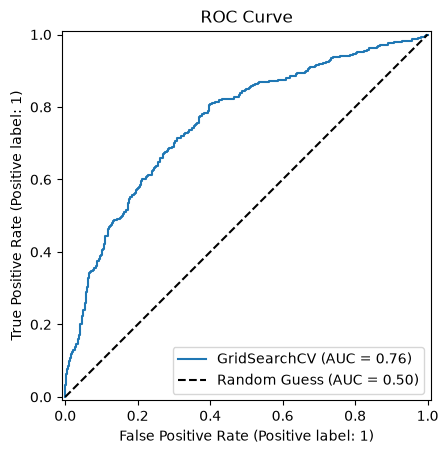

In [13]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

# calculate AUC
auc_score = roc_auc_score(y_test, y_proba[:, 1])
# graph ROC
RocCurveDisplay.from_estimator(grid, X_test, y_test)
plt.plot([0, 1], [0, 1], "k--", label="Random Guess (AUC = 0.50)") # Baseline
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()

# Results

| Forecast (958 test fights) | Accuracy | Log loss |
|---|---|---|
| Always pick the red corner | 55.3% | N/A |
| Stats only | 61.4% | 0.646 |
| Betting market | 69.8% | 0.589 |
| Stats + market (final model) | 70.4% | 0.586 |

After running the model, it is evident that using only statistics, a machine learning model is unable to beat the market. However, through a combination of statistics and the market odds, is appears that the model has an ever so slight edge over just the market (has a lower log loss, and a higher accuracy). In addition, the model boasts precision and recall of 0.7, which is quite good considering the limited amount of data it was able to use.

However, because the model performed only slightly better than the market, it is important to test if there is a statistically significant difference between the model and the market.

### Calibration Curve
A calibration curve bins a model into a handful of points and then compares them to a perfect prediction. Essentially, it compares how good the model performs compared to reality. Visually, it is evident that the stats + market model performs similarly to the market alone.

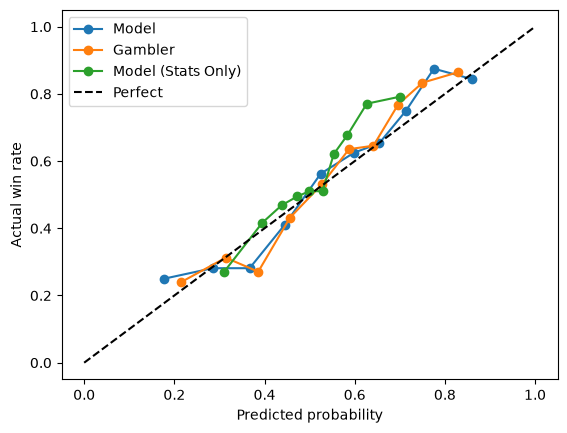

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# calculate the probability of the model
p_model_stats = y_proba_stats[:, 1]
p_model  = y_proba[:, 1]
p_market = 1 / (1 + np.exp(-X_test['odds_logit'].values))

# iterate through the gambler and the model
for name, p in [("Model", p_model), ("Gambler", p_market), ("Model (Stats Only)", p_model_stats)]:
    # split into quantile bins
    frac, mean_p = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    # plot the two graphs
    plt.plot(mean_p, frac, marker="o", label=name)

# plot along diagonal line
plt.plot([0, 1], [0, 1], "k--", label="Perfect")
# label axes
plt.xlabel("Predicted probability")
plt.ylabel("Actual win rate")
plt.legend()
plt.show()

### Bootstrapped Accuracy Difference

Bootstrap the difference between the stats + market model, and the market's predictions and determine how much it differs. It is an incredibly small amount.

In [15]:

import numpy as np

# bootstrap the model's accuracy difference
d = (y_pred == np.asarray(y_test)).astype(int) - (gambler_logit == np.asarray(y_test)).astype(int)
n = len(d)
rng = np.random.default_rng(0)

# get all of the boots
boots = [d[rng.integers(0, n, n)].mean() for x in range(10000)]
# calculate mean accuracy difference
print("Accuracy diff:", d.mean())
# on 95% CI
print("Accuracy diff on 95% CI:", np.percentile(boots, [2.5, 97.5]))

Accuracy diff: 0.003131524008350731
Accuracy diff on 95% CI: [-0.01148225  0.0177453 ]


### McNemar's Test

McNemar's Test is used to determine if the error rates between the stats + market model and the market by itself differ by a significant amount. It compares where the market and the stats + market model differ, and checks if one was correct more often. In this scenario, there is not a statistical difference between both error rates (p-value > 0.05), indiciating that one model is not better than another.

In [16]:
from statsmodels.stats.contingency_tables import mcnemar

# where gambler and model agree, and are both correct
both_correct = X_test[(gambler_logit == y_pred) & (y_pred == test_df['label'])]
# where only gambler is correct
gambler_only_correct = X_test[(gambler_logit != y_pred) & (gambler_logit == test_df['label'])]
# where only model is correct
model_only_correct = X_test[(gambler_logit != y_pred) & (y_pred == test_df['label'])]
# where both the model and gambler are wrong
both_incorrect = X_test[(gambler_logit == y_pred) & (y_pred != test_df['label'])]

# create contingency table
contingency_table = [
    [len(both_correct), len(model_only_correct)],
    [len(gambler_only_correct), len(both_incorrect)]
]

# calculate p-value of being being from different models
result = mcnemar(contingency_table, exact=False, correction=True)

# determine if significant difference in error rates
if result.pvalue < 0.05:
    better = "model" if len(model_only_correct) > len(gambler_only_correct) else "gambler"
    print(f"Error rates differ significantly; the {better} is more accurate.")
else:
    print("No significant difference in error rates.")
    
print(f"p-value: {result.pvalue:.3f}")

No significant difference in error rates.
p-value: 0.779


### Forecast Encompassing Test

In order to compare the forecasts between the model, I used [Forecast Encompassing](https://economicsnetwork.ac.uk/showcase/cook_encompassing). Forecast encompassing determines if one forecast (series of model predictions) is encompassed by another. If the coefficient of the model is nonzero and if the associated p-value's magnitude is notable (< 0.05). Because none of the models have a p-value below 0.05, neither model provides enough capability to cover the other.

In [17]:
import numpy as np
import statsmodels.api as sm

y = np.asarray(y_test)
# convert model's probabilities to logit
logit = lambda p: np.log(p / (1 - p))

# add a ones column and convert into features
X_enc = sm.add_constant(np.column_stack([X_test['odds_logit'].values, logit(p_model)]))
# fit to logistic regression
fit = sm.Logit(y, X_enc).fit(disp=0)
# describe fit
print(fit.summary(xname=["test_data", "gambler", "model"]))

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                  958
Model:                          Logit   Df Residuals:                      955
Method:                           MLE   Df Model:                            2
Date:                Mon, 12 Oct 2026   Pseudo R-squ.:                  0.1498
Time:                        20:33:39   Log-Likelihood:                -559.91
converged:                       True   LL-Null:                       -658.59
Covariance Type:            nonrobust   LLR p-value:                 1.390e-43
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
test_data      0.0511      0.074      0.693      0.488      -0.093       0.196
gambler        0.3729      0.462      0.807      0.420      -0.533       1.278
model          0.7242      0.400      1.809      0.0

# Conclusion

The statistics model was able to predict the winner more accurately than picking the red corner, but not as accurate as the betting market. Combining the stats and market did produce a model with a higher accuracy, but no statistical test was able to prove that the improvement was significant.